# P7.16 — Passa-faixa com a janela fixa de menor comprimento

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., p. 380 · DTA §2.1 (item 8) e §4 (Resolução P7.16).

> *Design a bandpass filter using a fixed window design technique that has the minimum length and that satisfies the following specifications: lower stopband edge = 0.3π, As = 40 dB, upper stopband edge = 0.6π; lower passband edge = 0.4π, Rp = 0.5 dB, upper passband edge = 0.5π. Provide a plot of the log-magnitude response in dB and stem plot of the impulse response.*

| Parâmetro | Valor |
|---|---|
| Rejeição inferior | $0 \le \omega \le 0.3\pi$, $A_s = 40$ dB |
| Passagem | $0.4\pi \le \omega \le 0.5\pi$, $R_p = 0.5$ dB |
| Rejeição superior | $0.6\pi \le \omega \le \pi$ |
| Objetivo | janela fixa e **comprimento mínimo** |

As bordas são as mesmas do P7.11. Só $A_s$ muda: de 50 para 40 dB.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método

$\Delta\omega = 0.1\pi$; cortes $\omega_{c1} = 0.35\pi$, $\omega_{c2} = 0.55\pi$; $h(n) = [h_{LP}(n;\omega_{c2}) - h_{LP}(n;\omega_{c1})]\,w(n)$.

**Candidatas.** Pela Tabela 7.1, retangular (21 dB) e Bartlett (25 dB) não alcançam 40 dB. Restam Hann (44 dB), Hamming (53 dB) e Blackman (74 dB).

**Dois critérios de "comprimento mínimo":**

1. **Pela Tabela 7.1** (o critério do DTA): $M = \lceil k\pi/\Delta\omega \rceil + 1$, com $k = 6.2,\ 6.6,\ 11$, o que dá Hann 63, Hamming 67, Blackman 111. A Hann vence porque tem a transição tabelada mais estreita entre as janelas que alcançam 40 dB.
2. **Pela medição** (decisão D5): para cada janela, varrem-se os comprimentos (pares e ímpares, pois o passa-faixa admite Tipo 2) e toma-se o menor que atende $R_p$ e $A_s$ medidos.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2.fir import analysis
from dsp_av2.specs import P7_16 as SPEC
from exercises import p7_16

results = p7_16.evaluate_windows()
print("Janela     A_s tabela   M tabela   M mínimo medido")
from dsp_av2.fir.windows import FIXED_WINDOWS
for r in results:
    print(f"{r.window:9s}    {FIXED_WINDOWS[r.window].min_stopband_db:4.0f} dB       {r.M_table:3d}           {r.M_min:3d}")

Janela     A_s tabela   M tabela   M mínimo medido
hann           44 dB        63            62
hamming        53 dB        67            61
blackman       74 dB       111            82


## 2. Por que a medição dá comprimentos menores e inverte a ordem Hann × Hamming?

O $\Delta\omega$ da Tabela 7.1 é a largura de transição necessária para a resposta atingir a **atenuação plena da janela**: 44 dB na Hann, 53 dB na Hamming. Este enunciado exige só 40 dB.

- A **Hamming** tem 13 dB de sobra (53 − 40). A resposta cruza −40 dB bem antes do fim da transição tabelada, e o filtro pode encolher de 67 para 61.
- A **Hann** tem só 4 dB de sobra (44 − 40), e encolhe pouco: de 63 para 62.

Pela tabela, a Hann parece melhor por ter a transição mais estreita. Na medição, a Hamming vence porque tem mais folga de atenuação para trocar por transição.

A varredura de cada janela mostra o primeiro comprimento que atende:

In [3]:
from dsp_av2.fir.design import design_fixed_window
wg = analysis.frequency_grid(SPEC.edges, analysis.DENSE_GRID_POINTS)
for r in results[:2]:
    print(f"--- {r.window}")
    print(" M    Rp [dB]   As [dB]   atende?")
    for M in range(r.M_min - 3, r.M_min + 2):
        dm = design_fixed_window(SPEC, r.window, M=M)
        rp, as_ = analysis.measure_rp_as(dm.h, SPEC.passbands, SPEC.stopbands, wg)
        print(f"{M:3d}   {rp:7.4f}   {as_:6.2f}    {'sim' if rp <= SPEC.rp_db and as_ >= SPEC.as_db else 'não'}")

--- hann
 M    Rp [dB]   As [dB]   atende?
 59    0.1944    36.20    não
 60    0.1758    37.60    não
 61    0.1580    39.14    não
 62    0.1409    40.86    sim
 63    0.1246    42.83    sim
--- hamming
 M    Rp [dB]   As [dB]   atende?
 58    0.1568    35.96    não
 59    0.1348    37.45    não
 60    0.1149    38.96    não
 61    0.0982    40.64    sim
 62    0.0834    42.20    sim


## 3. Projeto final: Hamming, $M = 61$

$M = 61$ é ímpar (Tipo 1, $\alpha = 30$).

Janela: hamming;  M = 61;  α = 30;  Tipo 1


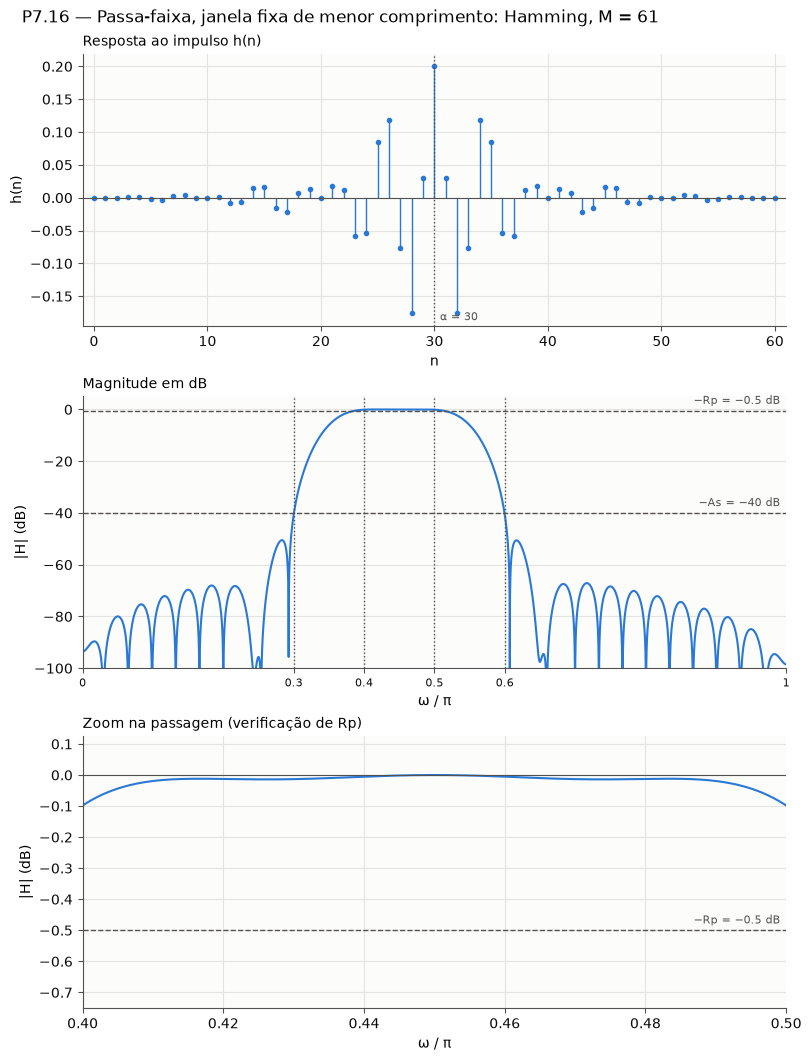

In [4]:
d = p7_16.design()
print(f"Janela: {d.window};  M = {d.M};  α = {d.alpha:g};  Tipo {analysis.linear_phase_type(d.h)}")
fig = p7_16.plot(d)
plt.show()

Pedidos: stem de $h(n)$ e log-magnitude em dB. O zoom na passagem foi acrescentado para mostrar $R_p$.

## 4. Validação contra a especificação

In [5]:
print(p7_16.validate(d))
from scipy.signal import firwin
ref = firwin(d.M, list(d.cutoffs), window="hamming", pass_zero=False, scale=False)
print("\nmax |h − h_firwin| =", np.max(np.abs(d.h - ref)))

Validação P7.16 (Tipo 1 de fase linear)
  [OK  ] Rp [dB] (grade livro): 0.0982 <= 0.5000  (folga +0.4018)
  [OK  ] As [dB] (grade livro): 40.6356 >= 40.0000  (folga +0.6356)
  [OK  ] Rp [dB] (grade densa): 0.0982 <= 0.5000  (folga +0.4018)
  [OK  ] As [dB] (grade densa): 40.6356 >= 40.0000  (folga +0.6356)
  Resultado: ATENDE à especificação

max |h − h_firwin| = 9.71445146547012e-17


## 5. Conclusão

- **Pelo critério da Tabela 7.1** (o do DTA), a resposta seria Hann com $M = 63$.
- **Pelo critério medido** (adotado, decisão D5), a resposta é **Hamming com $M = 61$** (Tipo 1, $\alpha = 30$): $R_p \approx 0.098$ dB $\le 0.5$ dB e $A_s \approx 40.64$ dB $\ge 40$ dB.
- A Hann chega a no mínimo $M = 62$, e a Blackman a $M = 82$.
- A inversão Hann → Hamming ocorre porque o $\Delta\omega$ da tabela vale para a atenuação plena da janela. Com uma exigência de só 40 dB, a janela com mais sobra de atenuação (Hamming, 53 dB) troca essa sobra por uma transição mais estreita.